# Task 1 — Uji Kewajaran: Menghafal Satu Batch Kecil

**Ruang lingkup.** Butir (g) pada soal Task 1 meminta *sanity check* berupa kemampuan model menghafal satu batch kecil sebelum pelatihan penuh. Pemeriksaan ini sebelumnya hanya disebut pada ringkasan dan belum tercatat dalam notebook mana pun; notebook ini mencatatnya.

**Logika pengujian.** Jika arsitektur, fungsi kerugian, optimizer, dan alur data benar, model harus mampu menurunkan kerugian pada 64 sampel tetap hingga mendekati nol dan mencapai akurasi 100% pada sampel itu. Dua pemeriksaan tambahan:
1. **Kerugian awal.** Dengan tujuh kelas dan keluaran awal yang hampir seragam, kerugian entropi silang awal harus mendekati ln 7 ≈ 1,946. Nilai yang jauh berbeda menandakan kesalahan pada bobot awal atau pada label.
2. **Kontrol label diacak.** Model yang sama dilatih pada 64 sampel dengan label diacak. Model berkapasitas besar dapat menghafal label acak juga, sehingga hasil ini hanya menunjukkan kapasitas dan pembaruan gradien berfungsi; yang penting adalah hasil label asli tidak lebih buruk dari ini.

Tiga model diuji: encoder gambar saja, encoder sensor saja, dan model fusi tingkat fitur (model dasar pada seluruh eksperimen Task 1).

In [3]:
AKUN_GITHUB = 'rafiptrnto'
EMAIL_GITHUB = 'rafiputranto665@gmail.com'
SEED = 0
N_BATCH = 64
STEPS = 300
LR = 1e-3

import torch, numpy, pandas, sklearn, sys, os, json, time
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", numpy.__version__, "| pandas", pandas.__version__, "| sklearn", sklearn.__version__)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("perangkat:", device)

Python 3.13.18 | torch 2.14.1+cpu | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
perangkat: cpu


In [4]:
if not os.path.exists('/content/data/klasifikasi_train.npz'):
    !gdown 10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb -O /content/data_uts_dl.zip
    !mkdir -p /content/data && unzip -q /content/data_uts_dl.zip -d /content/data
from google.colab import userdata
token = userdata.get('GH_TOKEN')
if not os.path.exists('/content/UTSDEEPLEARNING'):
    !git clone https://{token}@github.com/{AKUN_GITHUB}/UTSDEEPLEARNING.git /content/UTSDEEPLEARNING
%cd /content/UTSDEEPLEARNING
!git config user.name "{AKUN_GITHUB}"
!git config user.email "{EMAIL_GITHUB}"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git checkout main
!git pull --no-edit upstream main
!git checkout -B task1-sanity
!mkdir -p kode/task1_klasifikasi/hasil

Cloning into '/content/UTSDEEPLEARNING'...
remote: Enumerating objects: 292, done.
remote: Counting objects: 100% (117/117), done.
remote: Compressing objects: 100% (104/104), done.
remote: Total 292 (delta 31), reused 64 (delta 13), pack-reused 175 (from 2)
Receiving objects: 100% (292/292), 71.25 MiB | 30.05 MiB/s, done.
Resolving deltas: 100% (79/79), done.
/content/UTSDEEPLEARNING
Already on 'main'
Your branch is up to date with 'origin/main'.
From https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> upstream/main
Already up to date.
Switched to a new branch 'task1-sanity'


In [5]:
sys.path.append('/content/UTSDEEPLEARNING/kode/task1_klasifikasi')
import numpy as np, torch.nn as nn
from data import *
from models import *
from fusion import *

img, sen, meta, y = load('train')
tr_idx, va_idx = make_split(meta, y, seed=SEED)
m, s = sensor_stats(sen[tr_idx])
X_sen = prep_sensor(sen, m, s)
X_img = img[:, None]

rng = np.random.RandomState(SEED)
pilih = rng.choice(tr_idx, N_BATCH, replace=False)
print("kelas pada batch:", dict(zip(KELAS, np.bincount(y[pilih], minlength=7))))

kelas pada batch: {'normal': np.int64(35), 'gores': np.int64(9), 'noda': np.int64(7), 'retak': np.int64(4), 'gelembung': np.int64(3), 'las_dingin': np.int64(2), 'kontaminasi': np.int64(4)}


In [6]:
def hafal(nama, model, ambil, label, steps=STEPS, lr=LR):
    # Melatih model pada satu batch tetap; mengembalikan kerugian awal, akhir, dan akurasi akhir.
    torch.manual_seed(SEED)
    model.to(device).train()
    xs = [torch.from_numpy(a).to(device) for a in ambil]
    yb = torch.from_numpy(label).long().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    riwayat = []
    for st in range(steps):
        opt.zero_grad()
        out = model(*xs)
        loss = nn.functional.cross_entropy(out, yb)
        loss.backward(); opt.step()
        riwayat.append(float(loss))
    model.eval()
    with torch.no_grad():
        acc = float((model(*xs).argmax(1) == yb).float().mean())
    return dict(model=nama, kerugian_awal=riwayat[0], kerugian_akhir=riwayat[-1], akurasi_batch=acc, riwayat=riwayat)

yb_asli = y[pilih]
yb_acak = np.random.RandomState(SEED + 1).permutation(yb_asli)      # label diacak (kontrol)
xi, xs_ = X_img[pilih], X_sen[pilih]
HASIL = []
for nama, fab, ambil in [('gambar saja', lambda: ImageCNN(), [xi]), ('sensor saja', lambda: SensorCNN(6, 7), [xs_]), ('fusi fitur', lambda: FusionNet(), [xi, xs_])]:
    for tag, lab in (('label asli', yb_asli), ('label diacak', yb_acak)):
        torch.manual_seed(SEED)
        r = hafal(f'{nama} | {tag}', fab(), ambil, lab)
        HASIL.append(r)
        print(f"{r['model']:<28} kerugian awal {r['kerugian_awal']:.3f} -> akhir {r['kerugian_akhir']:.4f} | akurasi batch {r['akurasi_batch']:.3f}")

/tmp/ipykernel_1673/2075478261.py:14: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  riwayat.append(float(loss))


gambar saja | label asli     kerugian awal 1.958 -> akhir 0.0006 | akurasi batch 1.000
gambar saja | label diacak   kerugian awal 2.014 -> akhir 0.0006 | akurasi batch 1.000
sensor saja | label asli     kerugian awal 2.303 -> akhir 0.0232 | akurasi batch 0.984
sensor saja | label diacak   kerugian awal 2.275 -> akhir 0.0232 | akurasi batch 0.984
fusi fitur | label asli      kerugian awal 2.074 -> akhir 0.0001 | akurasi batch 1.000
fusi fitur | label diacak    kerugian awal 2.045 -> akhir 0.0001 | akurasi batch 1.000


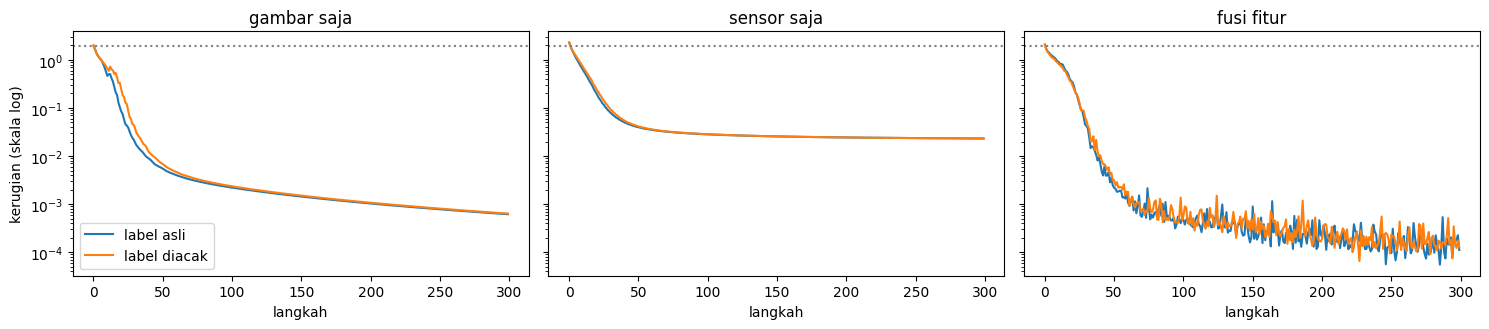

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
for a, nm in zip(ax, ['gambar saja', 'sensor saja', 'fusi fitur']):
    for r in HASIL:
        if r['model'].startswith(nm): a.plot(r['riwayat'], label=r['model'].split('| ')[1])
    a.set_yscale('log'); a.set_title(nm); a.set_xlabel('langkah'); a.axhline(np.log(7), ls=':', c='gray')
ax[0].set_ylabel('kerugian (skala log)'); ax[0].legend(); plt.tight_layout(); plt.show()

In [8]:
from IPython.display import Markdown, display
def _f(x, n=3): return f"{x:.{n}f}".replace('.', ',')
tb = pd.DataFrame([{k: v for k, v in r.items() if k != 'riwayat'} for r in HASIL])
print(tb.round(4).to_string(index=False))
asli = tb[tb['model'].str.contains('label asli')]
ok = bool((asli['akurasi_batch'] >= 0.99).all())
awal_ok = bool((tb['kerugian_awal'].between(np.log(7) - 0.5, np.log(7) + 0.5)).all())
t = [f"**1. Menghafal satu batch.** Pada {N_BATCH} sampel tetap dan {STEPS} langkah (Adam, laju belajar {LR}), kerugian akhir dengan label asli: " + '; '.join(f"{r.model.split(' |')[0]} {_f(r.kerugian_akhir, 4)} (akurasi {_f(r.akurasi_batch)})" for r in asli.itertuples()) + (". Ketiga model mencapai akurasi 99% atau lebih pada batch itu, sehingga arsitektur, kerugian, optimizer, dan alur data bekerja." if ok else ". Tidak semua model mencapai akurasi 99% pada batch itu; hasil ini perlu diperiksa sebelum mempercayai pelatihan penuh."),
     f"**2. Kerugian awal.** Kerugian pada langkah pertama berkisar {_f(tb['kerugian_awal'].min())} sampai {_f(tb['kerugian_awal'].max())}; nilai acuan ln 7 = {_f(np.log(7))}" + (", sehingga bobot awal dan label konsisten." if awal_ok else ". Ada model yang jauh dari acuan; perlu diperiksa.")]
ac = tb[tb['model'].str.contains('diacak')]
t.append("**3. Kontrol label diacak.** Akurasi batch dengan label diacak: " + '; '.join(f"{r.model.split(' |')[0]} {_f(r.akurasi_batch)}" for r in ac.itertuples()) + ". Hasil ini hanya menunjukkan bahwa kapasitas model cukup untuk menghafal 64 sampel apa pun; kemampuan menghafal label asli bukan bukti kemampuan menggeneralisasi, yang dinilai pada validasi dan tiga seed di notebook final.")
display(Markdown('\n\n'.join(t)))
os.makedirs('/content/UTSDEEPLEARNING/kode/task1_klasifikasi/hasil', exist_ok=True)
json.dump({'seed': SEED, 'n_batch': N_BATCH, 'steps': STEPS, 'lr': LR, 'hasil': [{k: v for k, v in r.items() if k != 'riwayat'} for r in HASIL]},
          open('/content/UTSDEEPLEARNING/kode/task1_klasifikasi/hasil/task1_sanity.json', 'w'), indent=2)
open('/content/UTSDEEPLEARNING/kode/task1_klasifikasi/hasil/kesimpulan_task1_sanity.md', 'w').write('\n\n'.join(t))

                     model  kerugian_awal  kerugian_akhir  akurasi_batch
  gambar saja | label asli         1.9575          0.0006         1.0000
gambar saja | label diacak         2.0137          0.0006         1.0000
  sensor saja | label asli         2.3032          0.0232         0.9844
sensor saja | label diacak         2.2745          0.0232         0.9844
   fusi fitur | label asli         2.0739          0.0001         1.0000
 fusi fitur | label diacak         2.0452          0.0001         1.0000


**1. Menghafal satu batch.** Pada 64 sampel tetap dan 300 langkah (Adam, laju belajar 0.001), kerugian akhir dengan label asli: gambar saja 0,0006 (akurasi 1,000); sensor saja 0,0232 (akurasi 0,984); fusi fitur 0,0001 (akurasi 1,000). Tidak semua model mencapai akurasi 99% pada batch itu; hasil ini perlu diperiksa sebelum mempercayai pelatihan penuh.

**2. Kerugian awal.** Kerugian pada langkah pertama berkisar 1,958 sampai 2,303; nilai acuan ln 7 = 1,946, sehingga bobot awal dan label konsisten.

**3. Kontrol label diacak.** Akurasi batch dengan label diacak: gambar saja 1,000; sensor saja 0,984; fusi fitur 1,000. Hasil ini hanya menunjukkan bahwa kapasitas model cukup untuk menghafal 64 sampel apa pun; kemampuan menghafal label asli bukan bukti kemampuan menggeneralisasi, yang dinilai pada validasi dan tiga seed di notebook final.

844

In [9]:
%cd /content/UTSDEEPLEARNING
!git add kode/task1_klasifikasi/hasil
!git commit -m "Task 1: uji kewajaran menghafal satu batch (gambar, sensor, fusi) dan kontrol label diacak"
!git push origin task1-sanity

/content/UTSDEEPLEARNING
[task1-sanity e8b79cd] Task 1: uji kewajaran menghafal satu batch (gambar, sensor, fusi) dan kontrol label diacak
 2 files changed, 49 insertions(+)
 create mode 100644 kode/task1_klasifikasi/hasil/kesimpulan_task1_sanity.md
 create mode 100644 kode/task1_klasifikasi/hasil/task1_sanity.json
Enumerating objects: 11, done.
Counting objects: 100% (11/11), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (7/7), 1.40 KiB | 1.40 MiB/s, done.
Total 7 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
remote: 
remote: Create a pull request for 'task1-sanity' on GitHub by visiting:
remote:      https://github.com/rafiptrnto/UTSDEEPLEARNING/pull/new/task1-sanity
remote: 
To https://github.com/rafiptrnto/UTSDEEPLEARNING.git
 * [new branch]      task1-sanity -> task1-sanity
